# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features

- URL del dataset utilizado para la pregunta 2: https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17


In [19]:
import os
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from pandas.plotting import scatter_matrix


In [12]:
# Codigo para descargar los datasets de manera online

path_sdss_dir = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
sdss_file = os.path.join(path_sdss_dir, "star_classification.csv")
df_sdss = pd.read_csv(sdss_file)
print("Dataset SDSS17 cargado correctamente.")

# 2. Descargar y cargar 
path_spotify= kagglehub.dataset_download("saichaitanyareddyai/spotify-tracks-dataset-audio-features")
spotify_file = os.path.join(path_spotify, "spotify-tracks-dataset-detailed.csv")
df_spotify = pd.read_csv(spotify_file)
print("Dataset Spotify cargado correctamente.")

Dataset SDSS17 cargado correctamente.


100%|██████████| 7.90M/7.90M [00:05<00:00, 1.45MB/s]

Extracting files...


Dataset Spotify cargado correctamente.


In [11]:
#Codigo para importar los datasets desde el proyecto

os.makedirs("data/raw", exist_ok=True)

path_sdss = "data/raw/star_classification.csv"
path_spotify = "data/raw/spotify-tracks-dataset-detailed.csv"


if os.path.exists(path_sdss):
    df_sdss = pd.read_csv(path_sdss)
    print("Dataset SDSS17 cargado correctamente.")
else:
    print(f"Error: Coloca el archivo descargado en la ruta '{path_sdss}'")

if os.path.exists(path_spotify):
    df_goodreads = pd.read_csv(path_spotify)
    print("Dataset Spotify cargado correctamente.")
else:
    print("Error")


Dataset SDSS17 cargado correctamente.
Dataset Spotify cargado correctamente.


## Parte 1 — Algoritmos de aprendizaje supervizado

El dataset elegido fue el `spotify-tracks-dataset-detailed.csv` por la cantidad de filas y columnas que tiene, ya que cumple con los requerimientos de la tarea. Además, el área de la música es interesante para nosotros, y poder usar un dataset de este dominio, permitirá ver cómo se ajusta un proceso de Machine Learning para este tipo de datos.


### 1.0 Dataset y variables

| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |

Este es un problema de entrenamiento supervizado, dado que el modelo puede ser entrenado con ejemplos etiquetados.  



> La variable continua $Y_1$ elegida es `popularity`.

> La variable discreta binaria $Y_2$ elegida es `explicit`.



<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

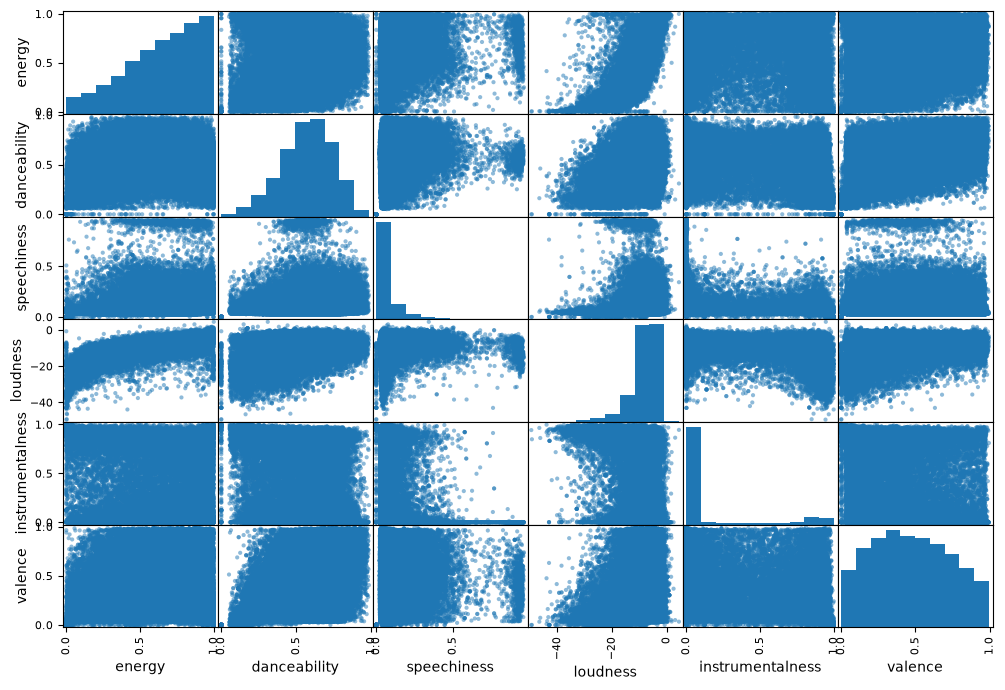

In [29]:

df_spotify.info()
df_spotify.describe()

#Conteno de nulos por columna 
print("\nConteo de nulos por columna:")
print(df_spotify.isnull().sum()[df_spotify.isnull().sum() > 0])

# Eleccion de variables predictorias
attributes = [ 'energy','danceability','speechiness','loudness', 'instrumentalness', 'valence' ]
scatter_matrix(df_spotify[attributes], figsize=(12, 8))
plt.show()

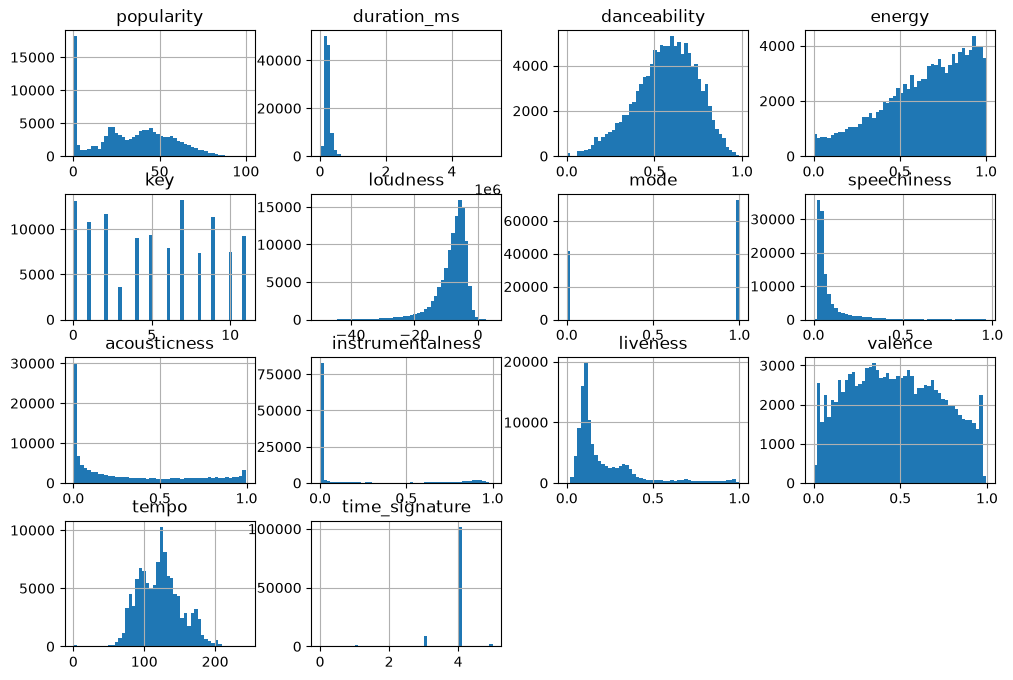

In [16]:

df_spotify.hist(bins=50, figsize=(12,8))
plt.show()

### Variables Predictorias 

Estas variables son 



### Entrenamiento




In [15]:


def shuffle_and_split_data(data, test_ratio):
    shuffle_indices = np.random.permutation(len(data))
    test_set_size = int(len(data)*test_ratio)
    test_indices = shuffle_indices[:test_set_size]
    train_indices = shuffle_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

print(f"\n{shuffle_and_split_data(df_spotify, 0.7)}")



(                     track_id                            artists  \
69167  6lDuFNpJKZvbR4fqEVtH66                    Nikhil Chandran   
37100  6YbhspuOar1D9WSSnfe7ds  Snoop Dogg;Wiz Khalifa;Bruno Mars   
73609  3v3jBfHHN27PP0ZO5RF8Aw                              Solee   
41823  0Ks7eVTVFmQAkyvDw6UHks                         Roffe Ruff   
56264  7JDWhC422Gtk1Bq0mL3OTC                         Bea Miller   
...                       ...                                ...   
35228  1qyv5mmcjAhnlNE7sc5isG                      Léo Magalhães   
32970  3Qh65CXtBe3vKmWe5fYbuY                          Kai Wachi   
35885  6LnbaR5hLhhJkmmwYuMfCD                      Cavalo De Pau   
63470  6vRkYTrWDzzVrZTqBJFR0u                               LiSA   
92854  0cDWCh9u46tQ4fN833vR9L                     Crazy Ken Band   

                                              album_name  \
69167                                Kanmashi Kannelledi   
37100  Mac and Devin Go to High School (Music from an...   
7

### Validación

### Prueba
